# Movilidad urbana y productividad económica en Latinoamérica (2024)

## Introducción

Análisis exploratorio de la relación entre la congestión vehicular, los tiempos de viaje y el PIB per cápita en ciudades latinoamericanas. Se integran datos de TomTom Traffic Index y OECD Cities para identificar patrones y posibles prioridades de inversión en infraestructura de transporte.

**Proyecto de análisis de datos | Sprint 5**

## 1. Carga y exploración de datos

Se importan las librerías y se inspeccionan las primeras filas de las dos fuentes.

In [9]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [10]:
# Cargar archivos (ejecución local o plataforma educativa)
from pathlib import Path

for data_dir in (Path("datasets"), Path("."), Path("/datasets")):
    if all((data_dir / filename).is_file() for filename in
           ("tomtom_traffic.csv", "oecd_city_economy.csv")):
        break
else:
    raise FileNotFoundError(
        "Coloca tomtom_traffic.csv y oecd_city_economy.csv en la carpeta datasets/ "
        "o junto al notebook."
    )

traffic = pd.read_csv(data_dir / "tomtom_traffic.csv")
eco = pd.read_csv(data_dir / "oecd_city_economy.csv")

In [11]:
# mostrar las primeras 5 filas de traffic
traffic.head()


,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [12]:
# mostrar las primeras 5 filas de eco
eco.head()


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


## 2. Exploración, limpieza y preparación de datos

### 2.1 Estructura y tipos de datos

Se revisan las dimensiones, los tipos de datos y los valores ausentes de cada fuente.

In [13]:
# Examinar la estructura de traffic
traffic.info()
display(traffic.head(3))
print("Valores nulos por columna:")
print(traffic.isna().sum())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232


Valores nulos por columna:
Country                           0
City                              0
UpdateTimeUTC                     0
JamsDelay                         0
TrafficIndexLive                  0
JamsLengthInKms                   0
JamsCount                         0
TrafficIndexWeekAgo               0
UpdateTimeUTCWeekAgo              0
TravelTimeLivePer10KmsMins        0
TravelTimeHistoricPer10KmsMins    0
MinsDelay                         0
dtype: int64


En la estructura del DataFrame traffic, se observa que:

- El dataset contiene 1,004,464 registros y 12 columnas relacionadas con la movilidad urbana, como congestión vehicular, cantidad de embotellamientos, tiempos de viaje y retrasos.
- Las columnas UpdateTimeUTC y UpdateTimeUTCWeekAgo son originalmente de tipo object, por lo que necesitan convertirse a datetime para poder analizar las fechas correctamente.
- Las columnas Country y City son de tipo object, lo cual es adecuado porque contienen información categórica.
- Las variables numéricas, como JamsDelay, TrafficIndexLive, JamsLengthInKms y MinsDelay, están almacenadas como float64, lo que permite realizar cálculos estadísticos.
- No se identificaron valores nulos en ninguna de las 12 columnas durante la exploración inicial.

En conclusión, el dataset presenta una estructura adecuada para el análisis, aunque es necesario convertir las fechas y estandarizar los nombres de las columnas antes de continuar con la agrupación y unión de los datos.

In [14]:
# Examinar la estructura de eco
eco.info()
display(eco.head(3))
print("Valores nulos por columna:")
print(eco.isna().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"


Valores nulos por columna:
Year               0
City               0
Country            0
City GDP/capita    0
Unemployment %     0
PM2.5 (μg/m³)      0
Population (M)     0
dtype: int64


En la estructura del DataFrame eco, se observa que:

- El dataset contiene 30 registros y 7 columnas con información económica y ambiental de distintas ciudades.
- La columna Year es de tipo int64, por lo que tiene el formato adecuado para trabajar con años.
- Las columnas City y Country son de tipo object, lo cual es correcto porque contienen nombres de ciudades y países.
- Las columnas City GDP/capita, Unemployment %, PM2.5 (μg/m³) y Population (M) están almacenadas como object, aunque contienen información numérica.
- Se identificaron valores con separadores de miles, comas decimales y símbolos de porcentaje, como 15.782,00 y 6.2%, que deben limpiarse antes de convertirlos a float.
- No se encontraron valores nulos en ninguna columna durante la revisión inicial.

En conclusión, la principal corrección consiste en transformar las variables económicas a tipos numéricos para poder calcular promedios, comparar indicadores y relacionarlos con los datos de movilidad urbana.

### 2.2 Estandarización de nombres de columnas

Se adopta el formato `snake_case` para facilitar las transformaciones y la integración.

In [15]:
# Estandarizar los nombres de las columnas de traffic
traffic = traffic.rename(columns={
    'Country': 'country',
    'City': 'city',
    'UpdateTimeUTC': 'update_time_utc',
    'JamsDelay': 'jams_delay',
    'TrafficIndexLive': 'traffic_index_live',
    'JamsLengthInKms': 'jams_length_kms',
    'JamsCount': 'jams_count',
    'TrafficIndexWeekAgo': 'traffic_index_week_ago',
    'UpdateTimeUTCWeekAgo': 'update_time_utc_week_ago',
    'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10kms_mins',
    'TravelTimeHistoricPer10KmsMins': 'travel_time_hist_per_10kms_mins',
    'MinsDelay': 'mins_delay'
})

# verificar cambios
traffic.columns


Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins', 'travel_time_hist_per_10kms_mins',
       'mins_delay'],
      dtype='object')

In [16]:
# Estandarizar los nombres de las columnas de eco
eco = eco.rename(columns={
    'Year': 'year',
    'City': 'city',
    'Country': 'country',
    'City GDP/capita': 'city_gdp_capita',
    'Unemployment %': 'unemployment_pct',
    'PM2.5 (μg/m³)': 'pm25',
    'Population (M)': 'population_m'
})

# verificar cambios
eco.columns


Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m'],
      dtype='object')

### 2.3 Conversión de formatos numéricos y fechas

Se convierten las fechas, se normalizan los separadores numéricos y se calcula la población total en unidades absolutas.

In [17]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(
    traffic['update_time_utc'], errors='coerce'
)

traffic['update_time_utc_week_ago'] = pd.to_datetime(
    traffic['update_time_utc_week_ago'], errors='coerce'
)

# verificar el cambio
traffic.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                           Non-Null Count    Dtype         
---  ------                           --------------    -----         
 0   country                          1004464 non-null  object        
 1   city                             1004464 non-null  object        
 2   update_time_utc                  1004464 non-null  datetime64[ns]
 3   jams_delay                       1004464 non-null  float64       
 4   traffic_index_live               1004464 non-null  float64       
 5   jams_length_kms                  1004464 non-null  float64       
 6   jams_count                       1004464 non-null  float64       
 7   traffic_index_week_ago           1004464 non-null  float64       
 8   update_time_utc_week_ago         1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10kms_mins  1004464 non-null  float64       
 10  travel_time_hist_per_10kms_min

In [18]:
# Limpia separadores y convierte columnas numéricas en eco

gdp_texto = eco['city_gdp_capita'].astype(str).str.strip()

tiene_coma = gdp_texto.str.contains(',', regex=False)

gdp_texto.loc[tiene_coma] = (
    gdp_texto.loc[tiene_coma]
    .str.replace('.', '', regex=False)
)

gdp_texto = gdp_texto.str.replace(',', '.', regex=False)

eco['city_gdp_capita'] = pd.to_numeric(
    gdp_texto, errors='coerce'
)

eco['unemployment_pct'] = pd.to_numeric(
    eco['unemployment_pct'].astype(str)
    .str.replace('%', '', regex=False)
    .str.replace(',', '.', regex=False)
    .str.strip(),
    errors='coerce'
)

eco['population_m'] = pd.to_numeric(
    eco['population_m'].astype(str)
    .str.replace(',', '.', regex=False)
    .str.strip(),
    errors='coerce'
)

# Calcula la población total en unidades absolutas
eco['population'] = eco['population_m'] * 1000000

# verificar el cambio
eco.info()
eco.head(3)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     object 
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000.0


## 3. Selección del periodo de análisis

Se extrae el año de los registros de tráfico y se filtran ambas fuentes para 2024.

In [19]:

# Extraer el año de las fechas en update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year

# Verificar cambio
traffic.head(3)


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [20]:
# Filtra los registros del año 2024
traffic_2024 = traffic[traffic['year'] == 2024].copy()

eco['year'] = pd.to_numeric(eco['year'], errors='coerce')
eco_2024 = eco[eco['year'] == 2024].copy()

# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0


## 4. Análisis y agregación de movilidad

Se calculan los promedios de las métricas de tráfico por ciudad, país y año.

In [21]:
# Calcular los promedios de trafico por ciudad, país y año

metricas = [
    'jams_delay',
    'traffic_index_live',
    'jams_length_kms',
    'jams_count',
    'mins_delay',
    'travel_time_live_per_10kms_mins',
    'travel_time_hist_per_10kms_mins'
]

# Asegurar que las métricas sean numéricas
traffic_2024[metricas] = traffic_2024[metricas].apply(
    pd.to_numeric, errors='coerce'
)

traffic_city_year_2024 = (
    traffic_2024
    .groupby(['city', 'country', 'year'])[metricas]
    .agg('mean')
    .reset_index()
)

# Mostrar resultado
traffic_city_year_2024.head()


,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


In [22]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


### Ciudad con mayor retraso promedio

La ciudad con el mayor retraso promedio por congestión vehicular es Ciudad de México (México), con un valor de 2,833.06 minutos de retraso acumulado en la red monitoreada por registro, en promedio durante 2024.

Este resultado fue superior al de Tokio, Japón, con 2,152.57 minutos, y Nueva York, Estados Unidos, con 2,133.40 minutos.

El resultado llama la atención porque demuestra que una ciudad latinoamericana encabeza los registros de retraso total por congestión dentro de las 387 ciudades analizadas.

Esto evidencia la importancia de estudiar la infraestructura de transporte, la eficiencia de las vías y las posibles alternativas de movilidad en las grandes zonas urbanas.

## 5. Integración de movilidad y economía

Se normalizan los nombres de las ciudades y se realiza una unión interna por ciudad y año.

In [23]:
# Seleccionar columnas clave de tráfico y economía
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_hist_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

# Usar .copy() para crear los dos nuevos datasets reducidos
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Estandarizar los nombres de ciudades
traffic_2024_small['city'] = (
    traffic_2024_small['city']
    .astype(str).str.strip().str.lower()
    .str.replace(' ', '-', regex=False)
)

eco_2024_small['city'] = (
    eco_2024_small['city']
    .astype(str).str.strip().str.lower()
    .str.replace(' ', '-', regex=False)
)

# Unir datasets
merged = pd.merge(
    traffic_2024_small,
    eco_2024_small,
    on=['city', 'year'],
    how='inner'
)

# Mostrar las primeras 5 filas
merged.head()


,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,"16,80",6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,"17,60",11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,"12,80",4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,"14,50",15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,"13,50",3700000.0


## 6. Visualización y análisis de relaciones

Se examinan las distribuciones de congestión y PIB per cápita mediante un boxplot, un histograma y un gráfico comparativo.

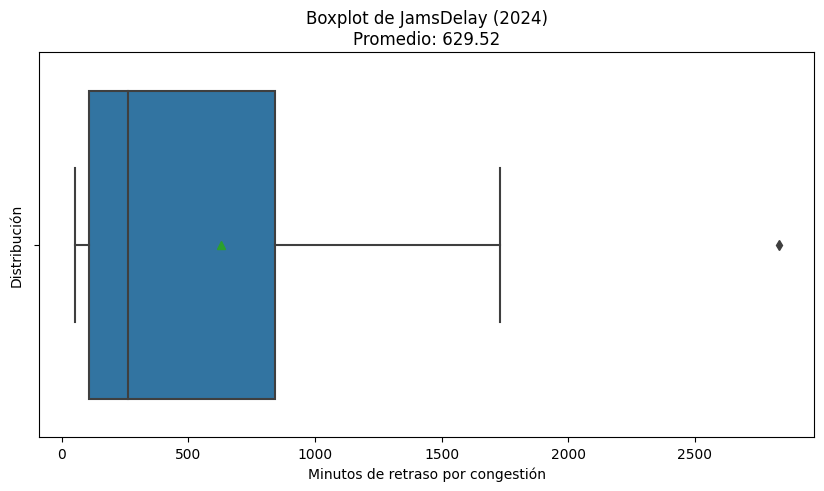

In [24]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay

plt.figure(figsize=(10, 5))
sns.boxplot(data=merged, x='jams_delay', showmeans=True)

plt.xlabel('Minutos de retraso por congestión')
plt.ylabel('Distribución')

# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()



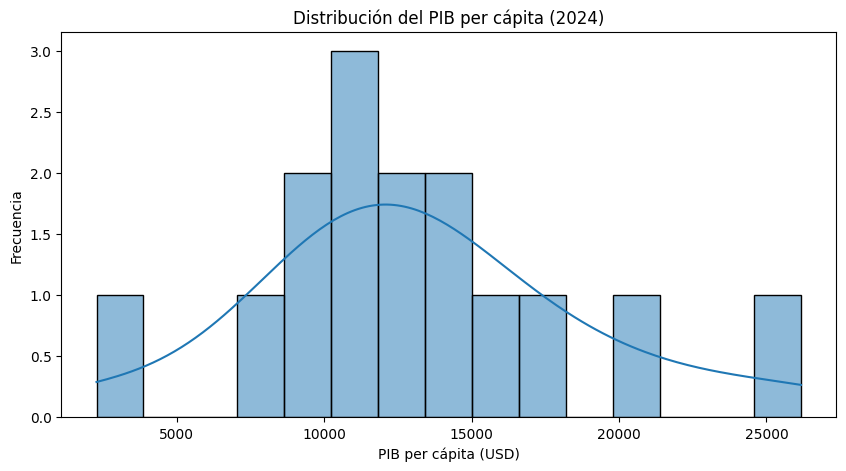

In [25]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=merged,
    x='city_gdp_capita',
    bins=15,
    kde=True
)

plt.title('Distribución del PIB per cápita (2024)')
plt.xlabel('PIB per cápita (USD)')
plt.ylabel('Frecuencia')

plt.show()



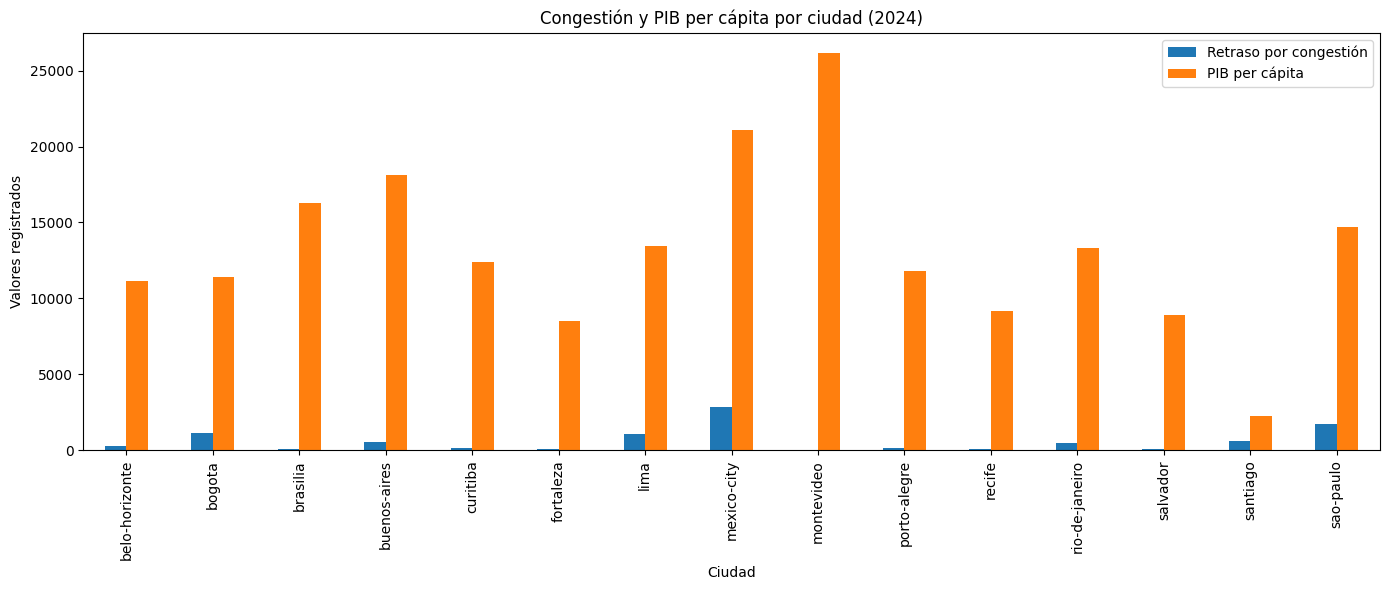

In [26]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad

merged.plot(
    kind='bar',
    x='city',
    y=['jams_delay', 'city_gdp_capita'],
    figsize=(14, 6)
)

plt.title('Congestión y PIB per cápita por ciudad (2024)')
plt.xlabel('Ciudad')
plt.ylabel('Valores registrados')
plt.xticks(rotation=90)
plt.legend(['Retraso por congestión', 'PIB per cápita'])
plt.tight_layout()

plt.show()


### Interpretación de las visualizaciones

Al analizar los resultados de las 15 ciudades latinoamericanas correspondientes a 2024, observé que no existe un patrón visual uniforme entre el PIB per cápita y la congestión vehicular.

Por ejemplo, Bogotá presenta aproximadamente 1,141.55 minutos de retraso agregado promedio por congestión y un PIB per cápita de 11,442 dólares. En comparación, Buenos Aires registra 571.09 minutos y un PIB per cápita de 18,117 dólares.

El boxplot muestra un promedio de congestión de 629.52 minutos y un valor atípico considerable, correspondiente a Ciudad de México. Esto indica que existen diferencias importantes entre las condiciones de tráfico de las ciudades analizadas.

Por otro lado, la distribución del PIB per cápita también presenta diferencias entre ciudades. Esto sugiere que la productividad económica no depende únicamente de la movilidad, sino también de otros factores relacionados con la infraestructura, la actividad económica y las características de cada ciudad.

En conclusión, los resultados permiten identificar posibles ciudades prioritarias para mejorar su infraestructura de transporte, aunque sería necesario calcular las correlaciones estadísticas y analizar más años para establecer una relación más sólida.

## 7. Exportación de resultados

Se guarda el dataset integrado en un archivo CSV sin índice.

In [27]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)


## 8. Resumen ejecutivo

El presente proyecto tuvo como objetivo analizar la relación entre la movilidad urbana y la productividad económica en distintas ciudades latinoamericanas durante 2024. Para ello, se utilizaron datos de TomTom Traffic Index y OECD Cities, considerando indicadores como los niveles de congestión, los tiempos de viaje, el PIB per cápita y el desempleo. Con este análisis se buscó identificar ciudades donde las condiciones del transporte podrían representar un área de oportunidad para mejorar su infraestructura y contribuir al desarrollo económico.

Inicialmente se trabajó con 1,004,464 registros de tráfico y 30 registros económicos. Después de filtrar la información correspondiente a 2024, el análisis global de movilidad incluyó 387 ciudades. Posteriormente, mediante la integración de ambas fuentes, se obtuvo un conjunto de datos combinado que comprende 15 ciudades de siete países latinoamericanos: Argentina, Brasil, Chile, Colombia, México, Perú y Uruguay. Esta información permitió comparar indicadores de movilidad y economía durante el mismo período.

El procedimiento consistió en explorar ambos datasets, identificar sus tipos de datos y revisar la existencia de valores faltantes. Posteriormente, se estandarizaron los nombres de las columnas, se corrigieron los formatos numéricos y se convirtieron las fechas para extraer el año correspondiente. Los registros de tráfico se agruparon por ciudad, país y año para calcular los promedios de las principales variables. Finalmente, se realizó una unión interna mediante pd.merge() y se elaboraron gráficos de caja, histogramas y gráficas comparativas para identificar patrones y valores atípicos.

Los resultados mostraron diferencias importantes en los niveles de congestión de las ciudades analizadas. Ciudad de México presentó el mayor retraso agregado promedio por congestión dentro del análisis global de tráfico, con 2,833.06 minutos. En el conjunto combinado, el promedio fue de 629.52 minutos. También se identificaron contrastes económicos: Bogotá registró 1,141.55 minutos de retraso promedio y un PIB per cápita de 11,442 dólares, mientras que Buenos Aires presentó 571.09 minutos y 18,117 dólares por habitante. Estos resultados sugieren que no existe una relación simple y uniforme entre la congestión vehicular y la productividad económica. Sin embargo, es necesario realizar análisis estadísticos adicionales para determinar la fuerza de dicha relación.

Considerando los resultados obtenidos, Bogotá podría representar una ciudad prioritaria para evaluar inversiones en infraestructura de transporte, debido a que combina niveles elevados de congestión con un PIB per cápita relativamente bajo frente a otras ciudades de la muestra. Ciudad de México también merece atención por la magnitud de los retrasos registrados, aunque presenta características económicas diferentes. Se recomienda ampliar el análisis a varios años, verificar la cobertura de las mediciones e incorporar indicadores de transporte público, población y demanda de movilidad antes de tomar decisiones de inversión.

En conclusión, el proyecto permitió aplicar herramientas de limpieza, transformación, agrupación, integración y visualización de datos para comprender mejor las diferencias entre movilidad urbana y actividad económica. La información obtenida constituye una base inicial para identificar oportunidades de mejora en la planificación del transporte y apoyar futuras decisiones relacionadas con el desarrollo de las ciudades latinoamericanas.